# Brain Tumor Segmentation with U-Net

Segmenting glioma sub-regions in multi-modal brain MRI (BraTS / Medical Segmentation Decathlon, Task01).

**Input:** 4 MRI modalities (FLAIR, T1, T1Gd, T2), 2D axial slices of 128×128  
**Output:** a class for every pixel — 0 background, 1 edema, 2 non-enhancing tumor, 3 enhancing tumor

## 1. Setup

In [1]:
import sys

sys.path.insert(0, "src")

import torch
import numpy as np
import matplotlib.pyplot as plt

from dataset import BrainSliceDataset

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("device:", device)

PyTorch: 2.11.0
device: mps


## 2. Data

The original 3D volumes (240×240×155, 4 modalities) were converted to 2D axial slices by `src/prepare_data.py` (all 484 training cases of the dataset):
- each modality z-score normalized over brain voxels
- all tumor slices kept + 10 random tumor-free brain slices per patient
- center-cropped to 192×192 and resized to 128×128
- split **by patient** into train / val / test (70 / 15 / 15) to avoid data leakage

In [2]:
DATA_DIR = "data/slices_full"  # all 484 patients ("data/slices" = 200-patient subset)

train_ds = BrainSliceDataset(DATA_DIR, "train", augment=False)
val_ds = BrainSliceDataset(DATA_DIR, "val")

print(f"train: {len(train_ds)} slices | val: {len(val_ds)} slices")

x, y = train_ds[40]
print("image:", x.shape, "| label:", y.shape, "| classes:", y.unique().tolist())

train: 26795 slices | val: 5848 slices
image: torch.Size([4, 128, 128]) | label: torch.Size([128, 128]) | classes: [0, 1, 2, 3]


### Example slice

Each modality highlights a different tumor sub-region:
- **FLAIR / T2** — the bright area around the tumor is **edema** (blue, class 1)
- **T1Gd** (contrast-enhanced) — the bright ring is the **enhancing tumor** (red, class 3); the dark center is **non-enhancing / necrotic** tissue (green, class 2)
- **T1** — mainly anatomical context

No single modality shows the whole tumor, which is why the model receives all four as input channels.

slice index: 280 | tumor pixels: 2296 | classes: [0, 1, 2, 3]


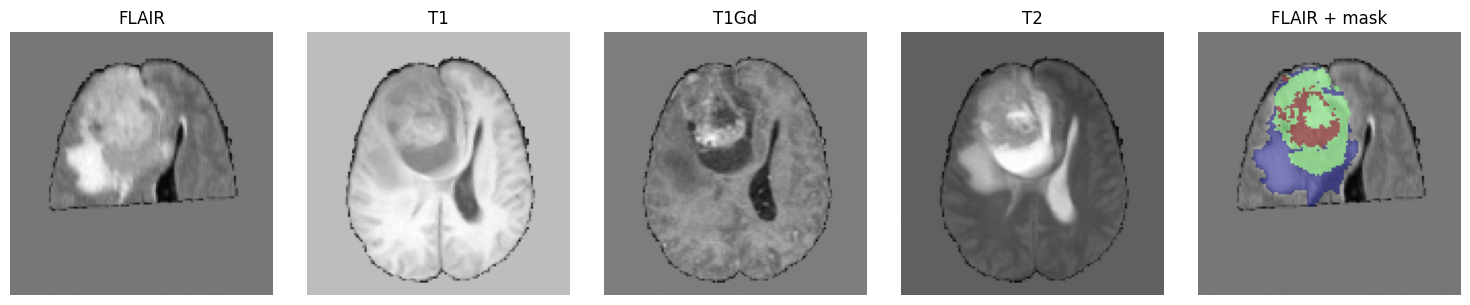

In [3]:
modalities = ["FLAIR", "T1", "T1Gd", "T2"]

# 1. among the first 300 slices, pick the one with the MOST tumor pixels
tumor_sizes = [(train_ds[i][1] > 0).sum().item() for i in range(300)]
best = int(np.argmax(tumor_sizes))
x, y = train_ds[best]
print("slice index:", best, "| tumor pixels:", tumor_sizes[best], "| classes:", y.unique().tolist())

x, y = x.numpy(), y.numpy()

# 2. rotate 90° only for display (NIfTI axis order differs from image order)
x = np.rot90(x, k=1, axes=(1, 2))
y = np.rot90(y, k=1)

# 3. plot
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for m in range(4):
    axes[m].imshow(x[m], cmap="gray")
    axes[m].set_title(modalities[m])
    axes[m].axis("off")

mask = np.ma.masked_where(y == 0, y)
axes[4].imshow(x[0], cmap="gray")
axes[4].imshow(mask, cmap="jet", alpha=0.5, vmin=1, vmax=3)
axes[4].set_title("FLAIR + mask")
axes[4].axis("off")

plt.tight_layout()
plt.show()

## 3. Evaluation metric: Dice score

Dice measures the overlap between the predicted mask **P** and the ground truth **T**:

$$\text{Dice} = \frac{2\,|P \cap T|}{|P| + |T|}$$

1 = perfect overlap, 0 = no overlap. Following BraTS, it is reported for three nested regions:
| Region | Classes |
|---|---|
| WT — whole tumor | 1, 2, 3 |
| TC — tumor core | 2, 3 |
| ET — enhancing tumor | 3 |

In [4]:
def dice_score(pred, target, min_class):
    p = pred >= min_class  # step 1: which pixels are "tumor" in pred
    t = target >= min_class  #         ... and in target
    inter = (p & t).sum().item()  # step 2: pixels where BOTH say tumor
    total = p.sum().item() + t.sum().item()
    if total == 0:  # no tumor anywhere and none predicted
        return 1.0
    return 2 * inter / total  # step 3: the formula


pred = torch.tensor([[0, 1, 1],
                     [0, 3, 2],
                     [0, 0, 0]])
target = torch.tensor([[0, 1, 0],
                       [0, 3, 3],
                       [0, 1, 0]])

print("WT:", dice_score(pred, target, 1))
print("TC:", dice_score(pred, target, 2))
print("ET:", dice_score(pred, target, 3))

WT: 0.75
TC: 1.0
ET: 0.6666666666666666


## 4. Model: U-Net

A U-Net from MONAI with 4 input channels (MRI modalities) and 4 output channels (one score per class for every pixel).
The encoder compresses the image to learn *what* is there; the decoder expands it back to full size to decide *where*; skip connections pass fine details from encoder to decoder so tumor borders stay sharp.

In [5]:
from torch.utils.data import DataLoader
from monai.networks.nets import UNet

torch.manual_seed(42)

# training data WITH augmentation (random flips etc.), validation WITHOUT
train_ds_aug = BrainSliceDataset(DATA_DIR, "train", augment=True)
train_dl = DataLoader(train_ds_aug, batch_size=16, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=16, shuffle=False)

model = UNet(
    spatial_dims=2,  # 2D images
    in_channels=4,  # FLAIR, T1, T1Gd, T2
    out_channels=4,  # background, edema, non-enhancing, enhancing
    channels=(32, 64, 128, 256, 512),  # filters at each level of the "U"
    strides=(2, 2, 2, 2),  # halve the image size at each level
    num_res_units=2,
).to(device)

print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M")

# sanity check: one batch through the model
x, y = next(iter(train_dl))
out = model(x.to(device))
print("input:", x.shape, "-> output:", out.shape, "| target:", y.shape)

parameters: 6.5 M
input: torch.Size([16, 4, 128, 128]) -> output: torch.Size([16, 4, 128, 128]) | target: torch.Size([16, 128, 128])


## 5. Training

- **Loss:** Dice + Cross-Entropy (`DiceCELoss`). The tumor covers only a few % of the image, so plain cross-entropy could score well by predicting "background" everywhere; the Dice term directly rewards overlap with the tumor.
- **Optimizer:** AdamW, learning rate 1e-3

In [6]:
from monai.losses import DiceCELoss

loss_fn = DiceCELoss(to_onehot_y=True, softmax=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)


def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)  # 1. forward pass
        loss = loss_fn(logits, y.unsqueeze(1))  # 2. calculate loss
        optimizer.zero_grad()  # 3. zero gradients
        loss.backward()  # 4. backpropagation
        optimizer.step()  # 5. update weights

        total_loss += loss.item()
    return total_loss / len(loader)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    preds, targets = [], []
    for x, y in loader:
        logits = model(x.to(device))
        # 4 scores per pixel -> 1 class; uint8 (1 byte) instead of int64 (8 bytes) saves RAM
        preds.append(logits.argmax(dim=1).to(torch.uint8).cpu())
        targets.append(y.to(torch.uint8))
    preds, targets = torch.cat(preds), torch.cat(targets)
    return {"WT": dice_score(preds, targets, 1),
            "TC": dice_score(preds, targets, 2),
            "ET": dice_score(preds, targets, 3)}

### Quick sanity check
A short run on 500 slices to verify the pipeline works and to estimate training time before the full run.

In [7]:
import time
from torch.utils.data import Subset

small_train = Subset(train_ds_aug, torch.randperm(len(train_ds_aug))[:500].tolist())
small_val   = Subset(val_ds, list(range(200)))
small_train_dl = DataLoader(small_train, batch_size=16, shuffle=True)
small_val_dl   = DataLoader(small_val, batch_size=16)

for epoch in range(1, 3):
    t0 = time.time()
    loss = train_one_epoch(model, small_train_dl)
    dice = evaluate(model, small_val_dl)
    print(f"epoch {epoch} | loss {loss:.4f} | "
          f"WT {dice['WT']:.3f}  TC {dice['TC']:.3f}  ET {dice['ET']:.3f} | {time.time()-t0:.0f}s")

epoch 1 | loss 1.9434 | WT 0.331  TC 0.115  ET 0.115 | 5s
epoch 2 | loss 1.4692 | WT 0.795  TC 0.596  ET 0.566 | 4s


### Full training

30 epochs on all training slices. The learning rate follows a cosine schedule (starts at 1e-3, slowly decays to ~0). After every epoch the model is evaluated on the full validation set, and the checkpoint with the best mean Dice is saved.

In [8]:
import os
os.makedirs("runs", exist_ok=True)

EPOCHS = 30
torch.manual_seed(42)

# start from a FRESH model (the one above already saw the small subset)
model = UNet(spatial_dims=2, in_channels=4, out_channels=4,
             channels=(32, 64, 128, 256, 512), strides=(2, 2, 2, 2),
             num_res_units=2).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = []
best_dice = 0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    loss = train_one_epoch(model, train_dl)
    dice = evaluate(model, val_dl)
    scheduler.step()

    mean_dice = (dice["WT"] + dice["TC"] + dice["ET"]) / 3
    history.append({"epoch": epoch, "loss": loss, **dice, "mean": mean_dice})

    saved = ""
    if mean_dice > best_dice:
        best_dice = mean_dice
        torch.save(model.state_dict(), "runs/best_model.pt")
        saved = "  <- saved"

    print(f"epoch {epoch:2d} | loss {loss:.4f} | WT {dice['WT']:.3f}  TC {dice['TC']:.3f}  "
          f"ET {dice['ET']:.3f} | mean {mean_dice:.3f} | {time.time()-t0:.0f}s{saved}")

print(f"\nbest mean val Dice: {best_dice:.3f}")

epoch  1 | loss 0.6032 | WT 0.905  TC 0.836  ET 0.845 | mean 0.862 | 223s  <- saved
epoch  2 | loss 0.4738 | WT 0.907  TC 0.838  ET 0.858 | mean 0.868 | 235s  <- saved
epoch  3 | loss 0.4583 | WT 0.911  TC 0.854  ET 0.859 | mean 0.875 | 264s  <- saved
epoch  4 | loss 0.4492 | WT 0.910  TC 0.852  ET 0.850 | mean 0.871 | 256s
epoch  5 | loss 0.4422 | WT 0.913  TC 0.853  ET 0.867 | mean 0.878 | 263s  <- saved
epoch  6 | loss 0.4365 | WT 0.915  TC 0.859  ET 0.862 | mean 0.878 | 301s  <- saved
epoch  7 | loss 0.4317 | WT 0.912  TC 0.855  ET 0.872 | mean 0.880 | 258s  <- saved
epoch  8 | loss 0.4274 | WT 0.912  TC 0.856  ET 0.857 | mean 0.875 | 252s
epoch  9 | loss 0.4237 | WT 0.914  TC 0.848  ET 0.868 | mean 0.877 | 261s
epoch 10 | loss 0.4202 | WT 0.913  TC 0.855  ET 0.873 | mean 0.880 | 267s  <- saved
epoch 11 | loss 0.3781 | WT 0.903  TC 0.819  ET 0.861 | mean 0.861 | 267s
epoch 12 | loss 0.2406 | WT 0.911  TC 0.861  ET 0.872 | mean 0.881 | 267s  <- saved
epoch 13 | loss 0.2213 | WT 0.91

## 6. Results

### Learning curves
Training history is saved to `runs/history.json` so results survive a kernel restart.

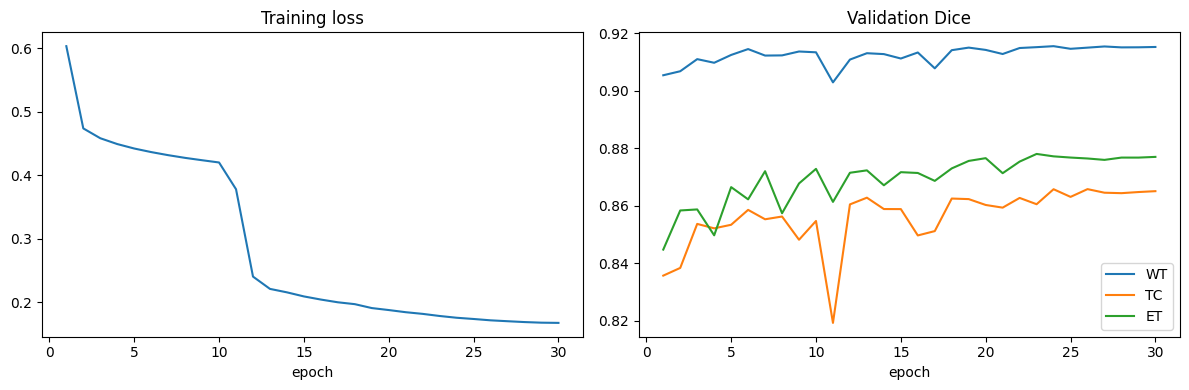

In [9]:
import json
import pandas as pd

with open("runs/history.json", "w") as f:
    json.dump(history, f, indent=2)

h = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(h["epoch"], h["loss"])
axes[0].set_title("Training loss")
axes[0].set_xlabel("epoch")

for region in ["WT", "TC", "ET"]:
    axes[1].plot(h["epoch"], h[region], label=region)
axes[1].set_title("Validation Dice")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig("runs/learning_curves.png", dpi=150)
plt.show()

**Observations**
- **Fast convergence:** mean validation Dice was already 0.862 after the first epoch and reached its best value, **0.886** (WT 0.916 · TC 0.866 · ET 0.877), at epoch 24. Epochs 7–30 added only ~0.006, so ~10 epochs would be enough for future experiments.
- **No overfitting:** training loss kept decreasing while validation Dice stayed flat instead of dropping.
- **Loss drop at epoch 11:** the training loss fell from 0.42 to 0.24 within two epochs while validation Dice did not improve. This is a property of the Dice loss: for slices where a class is absent, its Dice term stays close to 1 until the model becomes extremely confident that the class is absent, and then suddenly drops to ~0. It reflects a change in confidence, not better segmentation — which is why model selection uses validation Dice, not training loss.
- **ET and TC are harder than WT:** they are smaller regions, so each misclassified pixel has a bigger effect on the score.

 ### Test set evaluation

The checkpoint was selected using the validation set, so the validation score is slightly optimistic. The final, unbiased result is measured **once** on the test set — 74 patients the model has never seen during training or model selection.

In [11]:
test_ds = BrainSliceDataset(DATA_DIR, "test")
test_dl = DataLoader(test_ds, batch_size=16, shuffle=False)
print(f"test: {len(test_ds)} slices")

# load the BEST checkpoint (epoch 24), not the last one
model.load_state_dict(torch.load("runs/best_model.pt", map_location=device))

test_dice = evaluate(model, test_dl)
test_mean = sum(test_dice.values()) / 3
print(f"TEST | WT {test_dice['WT']:.3f}  TC {test_dice['TC']:.3f}  "
      f"ET {test_dice['ET']:.3f} | mean {test_mean:.3f}")

with open("runs/test_results.json", "w") as f:
    json.dump({**test_dice, "mean": test_mean}, f, indent=2)

test: 5952 slices
TEST | WT 0.903  TC 0.860  ET 0.851 | mean 0.871


| Split | WT | TC | ET | Mean |
|---|---|---|---|---|
| Validation (best epoch) | 0.916 | 0.866 | 0.877 | 0.886 |
| **Test** (74 unseen patients) | **0.903** | **0.860** | **0.851** | **0.871** |

The test score is only 0.015 below validation, so the model generalizes well to unseen patients. ET drops the most, as the smallest and most variable sub-region.

> **Note:** Dice here is computed on 2D slices (all tumor slices + 10 tumor-free slices per patient), pooled over all slices. It is **not directly comparable** to the official BraTS benchmark, which reports per-patient 3D Dice over the full volume.

### Qualitative results

Ground truth (doctor's annotation) vs. model prediction on test slices. Colors: blue = edema, green = non-enhancing tumor, red = enhancing tumor.

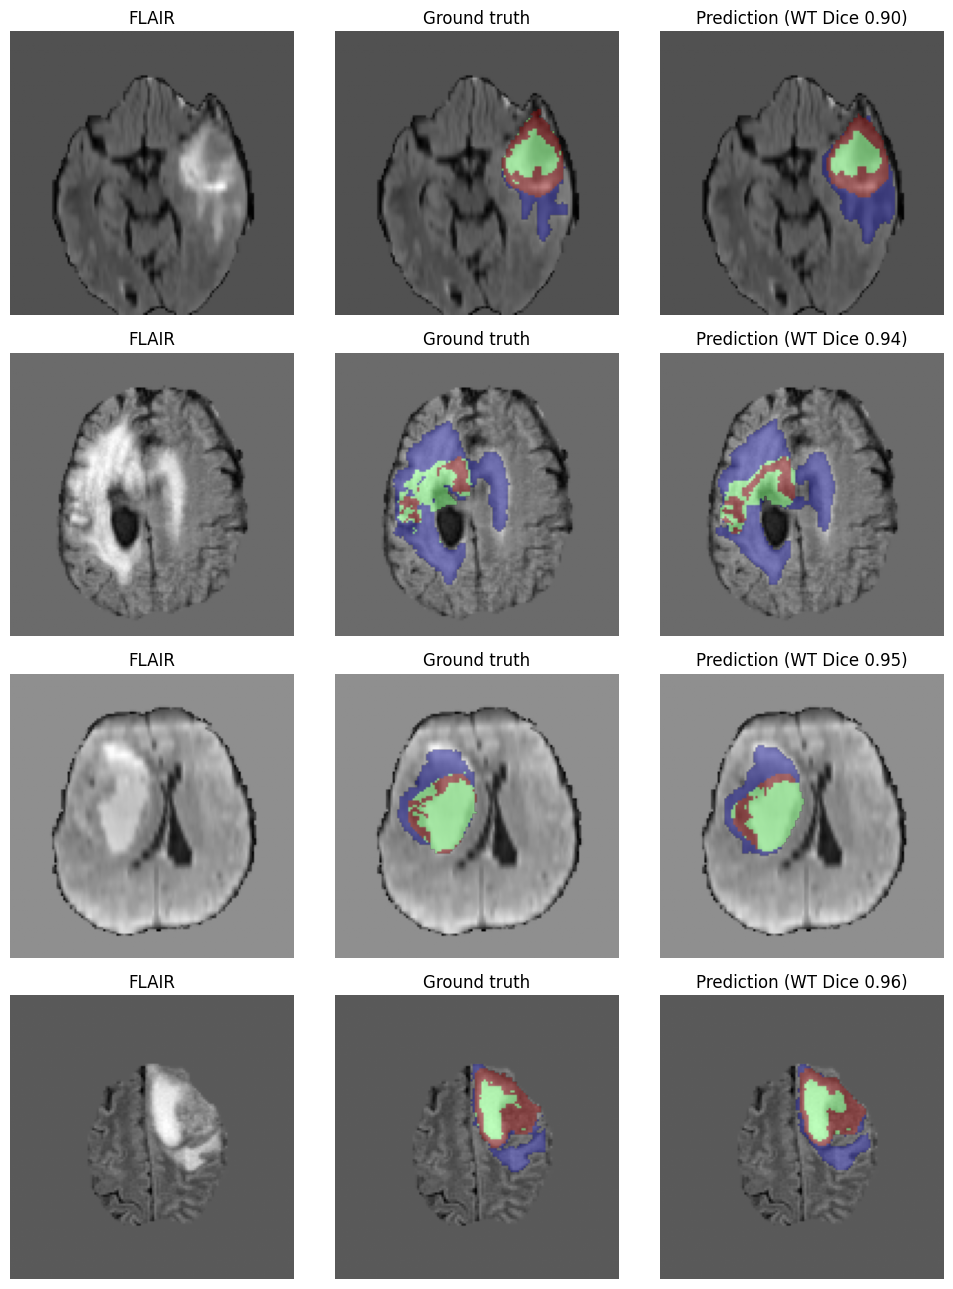

In [12]:
def show_prediction(idx, ax_row):
    x, y = test_ds[idx]
    with torch.no_grad():
        pred = model(x.unsqueeze(0).to(device)).argmax(dim=1)[0].cpu()

    d = dice_score(pred, y, 1)   # WT Dice of this single slice

    flair = np.rot90(x[0].numpy())
    gt    = np.rot90(y.numpy())
    pr    = np.rot90(pred.numpy())

    for ax, mask, title in zip(ax_row,
                               [None, gt, pr],
                               ["FLAIR", "Ground truth", f"Prediction (WT Dice {d:.2f})"]):
        ax.imshow(flair, cmap="gray")
        if mask is not None:
            ax.imshow(np.ma.masked_where(mask == 0, mask), cmap="jet", alpha=0.5, vmin=1, vmax=3)
        ax.set_title(title)
        ax.axis("off")


# pick 4 test slices with large tumors, spread across different patients
model.eval()
sizes = np.array([(test_ds[i][1] > 0).sum().item() for i in range(len(test_ds))])
candidates = np.where(sizes > 1000)[0]
chosen = candidates[np.linspace(0, len(candidates) - 1, 4).astype(int)]

fig, axes = plt.subplots(4, 3, figsize=(10, 13))
for row, idx in enumerate(chosen):
    show_prediction(idx, axes[row])
plt.tight_layout()
plt.savefig("runs/predictions.png", dpi=150)
plt.show()

The predictions closely match the annotations, including irregular shapes (row 2: a separate edema region next to the ventricle). Typical differences: the model tends to slightly **over-segment edema** (row 1) and draws **smoother borders** than the annotation — e.g. a continuous enhancing ring where the annotation is fragmented (row 3). These examples are large-tumor slices; failure cases are shown below.

### Failure cases

The 3 test slices with the lowest WT Dice (only slices with at least 200 tumor pixels, so that tiny tumors don't dominate).

worst WT Dice: [0.0, 0.0, 0.0]


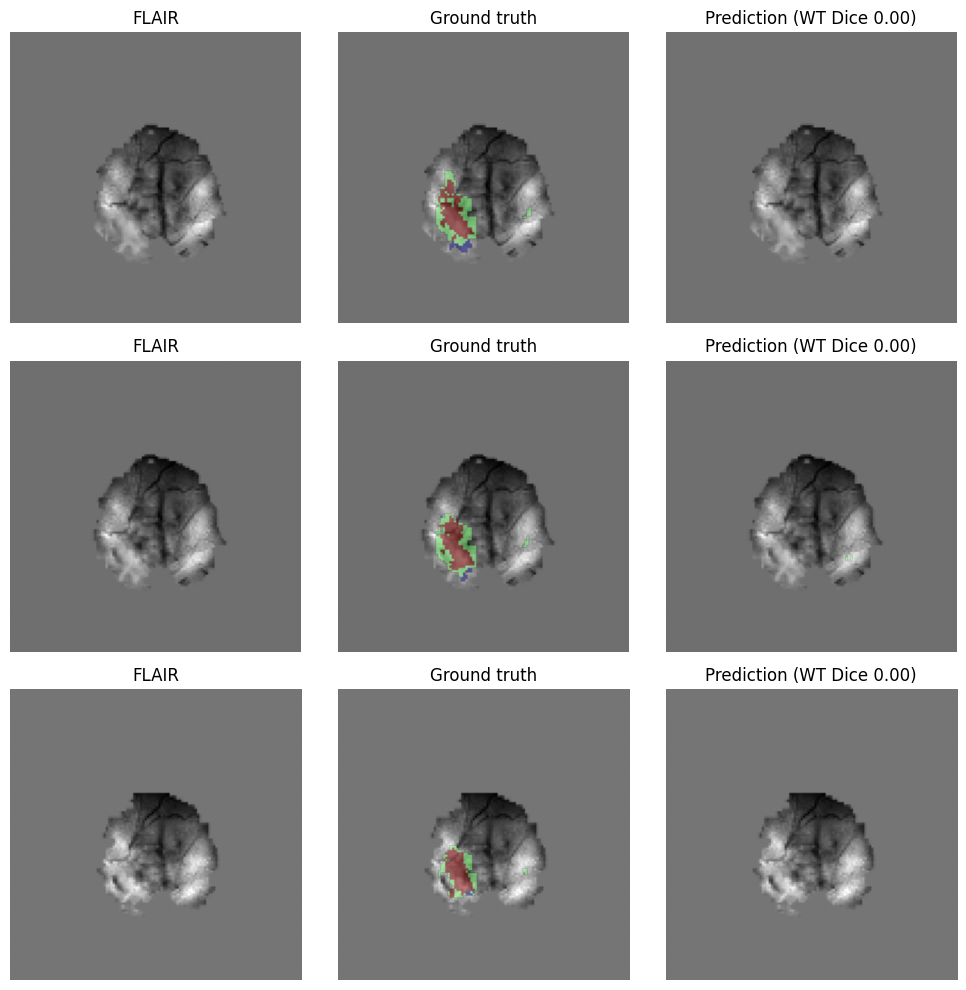

In [13]:
# 1. predict all test slices once and compute WT Dice per slice
slice_dice = []
with torch.no_grad():
    for x, y in test_dl:
        pred = model(x.to(device)).argmax(dim=1).cpu()
        for p, t in zip(pred, y):
            if (t > 0).sum() >= 200:
                slice_dice.append(dice_score(p, t, 1))
            else:
                slice_dice.append(None)       # too little tumor -> skip

# 2. take the 3 lowest
valid = [(d, i) for i, d in enumerate(slice_dice) if d is not None]
worst = [i for d, i in sorted(valid)[:3]]
print("worst WT Dice:", [round(slice_dice[i], 2) for i in worst])

# 3. plot them with the same function as before
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for row, idx in enumerate(worst):
    show_prediction(idx, axes[row])
plt.tight_layout()
plt.savefig("runs/failure_cases.png", dpi=150)
plt.show()

patient: BRATS_101 | slice: 65


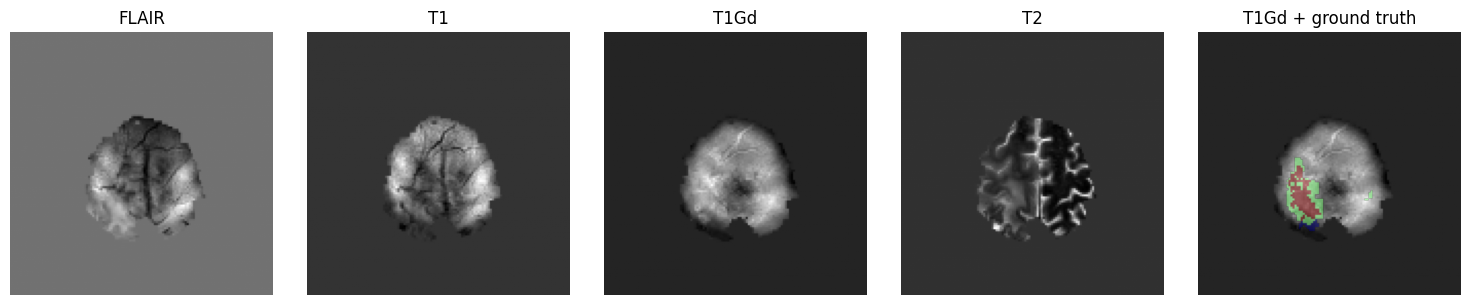

BRATS_101: 48 tumor slices, mean WT Dice 0.73


In [14]:
idx = worst[0]
case, slice_no = test_ds.index[idx]
print("patient:", case, "| slice:", slice_no)

x, y = test_ds[idx]
x, y = np.rot90(x.numpy(), axes=(1, 2)), np.rot90(y.numpy())

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for m in range(4):
    axes[m].imshow(x[m], cmap="gray")
    axes[m].set_title(modalities[m])
    axes[m].axis("off")
axes[4].imshow(x[2], cmap="gray")
axes[4].imshow(np.ma.masked_where(y == 0, y), cmap="jet", alpha=0.5, vmin=1, vmax=3)
axes[4].set_title("T1Gd + ground truth")
axes[4].axis("off")
plt.tight_layout()
plt.show()

# how does the model do on ALL slices of this patient?
pt = [i for i, (c, s) in enumerate(test_ds.index) if c == case]
pt_dice = [slice_dice[i] for i in pt if slice_dice[i] is not None]
print(f"{case}: {len(pt_dice)} tumor slices, mean WT Dice {np.mean(pt_dice):.2f}")

All three failure cases are **consecutive slices of the same patient (BRATS_101)**, located near the top of the brain. Inspecting all four modalities of the worst slice shows why:
- the annotated tumor is **not clearly distinguishable in any modality** — no FLAIR hyperintensity and no visible enhancing ring in T1Gd;
- the annotation contains almost **no edema**, unlike the typical pattern the model learned (tumor core surrounded by edema);
- the images show **strong intensity inhomogeneity** (bias field) and lower apparent quality than other cases.

The model misses these slices completely (Dice 0.00), but this patient's overall WT Dice is 0.73 — the failure is concentrated in a few atypical slices, not the whole case.

**Possible improvements:** N4 bias-field correction during preprocessing, stronger intensity augmentation, and giving the model 3D context (neighbouring slices as extra input channels, or a 3D U-Net).